# 04. 다중선형회귀 — 모형 비교, 최종 모형, 가정 검정

**입력**: `dataSet/student_clean.csv`, `dataSet/candidate_vars.csv`
**출력**: `out/04_*.csv`, `out/04_*.png`

03에서 변수 하나씩 본 결과를 **한 모형에 같이 넣어** 확인한다.
- 여러 변수를 함께 고려해도 각 변수의 관련성이 유지되는가 (조건부 회귀계수)
- 전체로 점수 변동을 얼마나 설명하는가 (R², adj. R²)
- 변수 표현 방식이 다른 모형들 중 어느 것이 나은가 (AIC·BIC·RMSE·MAE)

순서
1. 전처리 단계 비교 — 이상치를 경계값으로 대체하면 달라지는가? (달라지지 않음 → 기준선 채택)
2. 변수 표현 방식 비교 — `deep_work_sessions`와 `physical_activity_hours`를 연속형 / 그룹 더미 중 어떻게 넣을까? (4개 모형)
3. 최종 모형의 가정 검정 (선형성·정규성·등분산성·독립성)
4. 회귀계수 해석 — HC3 표준오차, 표준화계수 β

In [1]:
import pandas as pd
import numpy as np
import statsmodels.api as sm
import statsmodels.stats.api as sms
from statsmodels.stats.diagnostic import linear_reset
from statsmodels.stats.outliers_influence import variance_inflation_factor
from sklearn.metrics import root_mean_squared_error, mean_absolute_error
from scipy import stats
import matplotlib.pyplot as plt
from matplotlib import font_manager

font_manager.fontManager.addfont('NotoSansKR-Regular.ttf')
plt.rcParams['font.family'] = font_manager.FontProperties(fname='NotoSansKR-Regular.ttf').get_name()
plt.rcParams['axes.unicode_minus'] = False
pd.set_option('display.width', 180)
pd.set_option('display.float_format', '{:.4f}'.format)

df = pd.read_csv('dataSet/student_clean.csv')
TARGET = 'final_exam_score'

# 03에서 확정한 연속형 후보 13개
cont_vars = ['consistency_score', 'study_hours_per_day', 'focus_score', 'procrastination_index',
             'burnout_risk', 'revision_efficiency', 'motivation_level', 'social_media_hours',
             'stress_level', 'attendance_percentage', 'assignment_completion_rate',
             'financial_stress', 'sleep_hours']

## 0. 설계 행렬 만드는 함수

모형마다 두 변수의 표현만 바꾸므로 함수 하나로 만든다.

| 옵션 | 연속형 | 그룹 더미 |
|---|---|---|
| `deep_work` | 0~7회 그대로 | 6~7회 = 1 (기준 0~5회) |
| `physical` | 시간 그대로 | 0시간 초과 = 1 (기준 0시간) |

`mental_state`는 03의 사후검정대로 Balanced와 Distracted를 기준집단으로 합치고 Burnout·Focused 더미 2개를 넣는다.
`doomscrolling_before_sleep`은 이미 0/1이다.

In [2]:
def build_X(data, deep_work='continuous', physical='drop'):
    X = data[cont_vars].copy()
    X['doomscrolling_before_sleep'] = data['doomscrolling_before_sleep']
    X['mental_state_Burnout'] = (data['mental_state'] == 'Burnout').astype(int)
    X['mental_state_Focused'] = (data['mental_state'] == 'Focused').astype(int)

    if deep_work == 'continuous':
        X['deep_work_sessions'] = data['deep_work_sessions']
    else:
        X['deep_work_6_7'] = (data['deep_work_sessions'] >= 6).astype(int)

    if physical == 'continuous':
        X['physical_activity_hours'] = data['physical_activity_hours']
    elif physical == 'group':
        X['physical_active'] = (data['physical_activity_hours'] > 0).astype(int)
    # 'drop' 이면 넣지 않는다
    return sm.add_constant(X)


def fit_ols(X, y):
    """후진제거: p ≥ 0.05 인 변수를 하나씩(가장 큰 p부터) 빼면서 다시 적합한다."""
    X = X.copy()
    while True:
        fit = sm.OLS(y, X).fit()
        pvals = fit.pvalues.drop('const')
        if pvals.max() < 0.05:
            return fit
        drop = pvals.idxmax()
        print(f'  제거: {drop} (p = {pvals[drop]:.3f})')
        X = X.drop(columns=drop)


def metrics(fit, y, name):
    pred = fit.fittedvalues
    return {'모델': name, '변수 수': int(fit.df_model), 'R2': fit.rsquared, 'adj.R2': fit.rsquared_adj,
            'AIC': fit.aic, 'BIC': fit.bic,
            'RMSE': root_mean_squared_error(y, pred), 'MAE': mean_absolute_error(y, pred)}

y = df[TARGET]

## 1. 전처리 단계 비교 — 이상치 경계값 대체 효과

02에서 통계적 이상치가 1% 미만이었다. 그래도 IQR × 1.5 경계로 눌렀을 때 결과가 달라지는지 확인한다.
비교 모형은 EDA에서 유의했던 변수를 그대로 넣은 기본 모형(① 연속형).

스케일링은 하지 않는다 — 계수를 원래 단위로 읽는 게 해석에 편하고, 변수 간 비교는 뒤에서 표준화계수 β로 한다.

In [3]:
def clip_outliers(data, cols):
    out = data.copy()
    for c in cols:
        q1, q3 = out[c].quantile([0.25, 0.75])
        iqr = q3 - q1
        out[c] = out[c].clip(q1 - 1.5 * iqr, q3 + 1.5 * iqr)
    return out

df_clip = clip_outliers(df, cont_vars + ['deep_work_sessions', 'physical_activity_hours'])
print('대체된 값 수:', int((df_clip[cont_vars] != df[cont_vars]).sum().sum()))

X_base = build_X(df, deep_work='continuous', physical='continuous')
X_clip = build_X(df_clip, deep_work='continuous', physical='continuous')

step_cmp = pd.DataFrame([metrics(fit_ols(X_base, y), y, '0. 기준선'),
                         metrics(fit_ols(X_clip, y), y, '1. 이상치대체')]).set_index('모델')
step_cmp.to_csv('out/04_전처리단계_비교.csv')
step_cmp

대체된 값 수: 24
  제거: physical_activity_hours (p = 0.059)
  제거: physical_activity_hours (p = 0.061)


,변수 수,R2,adj.R2,AIC,BIC,RMSE,MAE
모델,,,,,,,
0. 기준선,17,0.8101,0.8089,19267.7448,19374.2079,8.1202,6.4823
1. 이상치대체,17,0.8101,0.8089,19268.0880,19374.5511,8.1207,6.4830


모든 지표 차이가 0.02% 미만이다. 이상치 대체는 효과가 없으니 **원본 그대로(기준선)** 쓴다.

## 2. 변수 표현 방식 비교 — 4개 모형

| 모형 | deep_work_sessions | physical_activity_hours |
|---|---|---|
| ① 기본 | 연속형 | 연속형 |
| ② 운동 그룹화 | 연속형 | 0 / 0 초과 더미 |
| ③ 딥세션 그룹화 | 0~5 / 6~7 더미 | 연속형 |
| ④ 둘 다 그룹화 | 0~5 / 6~7 더미 | 0 / 0 초과 더미 |

In [4]:
specs = {
    '① 기본 (연속형)':            dict(deep_work='continuous', physical='continuous'),
    '② physical 그룹화':          dict(deep_work='continuous', physical='group'),
    '③ deep_work 그룹화':         dict(deep_work='group',      physical='continuous'),
    '④ deep_work+physical 그룹화': dict(deep_work='group',      physical='group'),
}

fits, Xs = {}, {}
for name, kw in specs.items():
    Xs[name] = build_X(df, **kw)
    fits[name] = fit_ols(Xs[name], y)

model_cmp = pd.DataFrame([metrics(fits[n], y, n) for n in specs]).set_index('모델')
model_cmp.to_csv('out/04_모형비교.csv')
model_cmp

  제거: physical_activity_hours (p = 0.059)
  제거: physical_activity_hours (p = 0.239)


,변수 수,R2,adj.R2,AIC,BIC,RMSE,MAE
모델,,,,,,,
① 기본 (연속형),17,0.8101,0.8089,19267.7448,19374.2079,8.1202,6.4823
② physical 그룹화,18,0.8107,0.8094,19261.5112,19373.8889,8.1080,6.4684
③ deep_work 그룹화,17,0.8186,0.8175,19142.5115,19248.9746,7.9365,6.3463
④ deep_work+physical 그룹화,18,0.8189,0.8177,19139.7558,19252.1336,7.9296,6.3362


③·④가 ①·②보다 adj. R²는 높고 AIC·BIC·RMSE·MAE는 낮다. `deep_work_sessions`를 그룹으로 넣는 게 확실히 낫다.
③과 ④는 설명력·오차가 거의 같은데(adj. R² 차이 0.0002) ④는 변수가 하나 더 많고 BIC는 ③이 더 낮다.
→ **③ 을 최종 모형으로 선정** (간결하면서 성능 동일). 변수 17개.

(①·③에서 연속형 `physical_activity_hours`는 p > 0.05 라 후진제거로 빠졌다. 03의 단변량 결과(p = 0.82)와 같다.)

In [5]:
final = fits['③ deep_work 그룹화']
X_final = Xs['③ deep_work 그룹화'][final.model.exog_names]

print(f'n = {int(final.nobs)},  F({int(final.df_model)}, {int(final.df_resid)}) = {final.fvalue:.2f},  p = {final.f_pvalue:.2e}')
print(f'R² = {final.rsquared:.4f},  adj. R² = {final.rsquared_adj:.4f},  AIC = {final.aic:.1f},  BIC = {final.bic:.1f}')
print(f'RMSE = {root_mean_squared_error(y, final.fittedvalues):.4f},  MAE = {mean_absolute_error(y, final.fittedvalues):.4f}')

n = 2737,  F(17, 2719) = 721.87,  p = 0.00e+00
R² = 0.8186,  adj. R² = 0.8175,  AIC = 19142.5,  BIC = 19249.0
RMSE = 7.9365,  MAE = 6.3463


## 3. 최종 모형 가정 검정

| 가정 | 검정 | 귀무가설 |
|---|---|---|
| 선형성 | Ramsey RESET | 고차항을 넣어도 설명력이 늘지 않는다 |
| 정규성 | 잔차 Kolmogorov-Smirnov + Q-Q plot | 잔차가 정규분포다 |
| 등분산성 | Breusch-Pagan | 잔차 분산이 예측값과 무관하다 |
| 독립성 | Durbin-Watson | 잔차에 자기상관이 없다 (2에 가까우면 OK) |

In [6]:
resid = final.resid
reset = linear_reset(final, power=2, use_f=True)
z = (resid - resid.mean()) / resid.std()
ks = stats.kstest(z, 'norm')
bp_lm, bp_lm_p, bp_f, bp_f_p = sms.het_breuschpagan(resid, final.model.exog)
dw = sms.durbin_watson(resid)

assume = pd.DataFrame([
    ['선형성', 'Ramsey RESET F', reset.fvalue, reset.pvalue],
    ['정규성', 'Kolmogorov-Smirnov', ks.statistic, ks.pvalue],
    ['등분산성', 'Breusch-Pagan LM', bp_lm, bp_lm_p],
    ['등분산성', 'Breusch-Pagan F', bp_f, bp_f_p],
    ['독립성', 'Durbin-Watson', dw, np.nan],
], columns=['가정', '검정', '통계량', 'p-value'])
assume['판정'] = np.where(assume['p-value'].isna(), '2에 가까움 → 만족' if 1.5 < dw < 2.5 else '위배 의심',
                         np.where(assume['p-value'] >= 0.05, '만족', '위배'))
assume.to_csv('out/04_가정검정.csv', index=False)
assume

,가정,검정,통계량,p-value,판정
0,선형성,Ramsey RESET F,0.1822,0.6695,만족
1,정규성,Kolmogorov-Smirnov,0.0148,0.5828,만족
2,등분산성,Breusch-Pagan LM,13.4142,0.7080,만족
3,등분산성,Breusch-Pagan F,0.7877,0.7093,만족
4,독립성,Durbin-Watson,1.9575,NaN,2에 가까움 → 만족


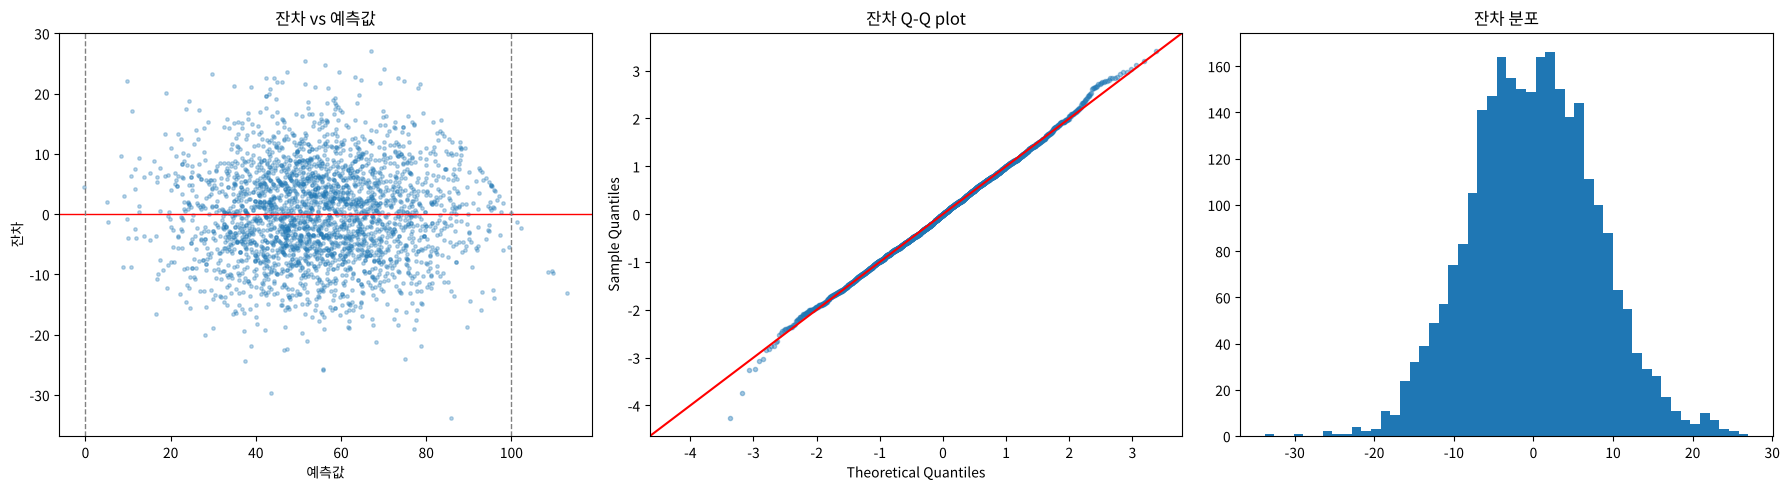

예측값 범위: -0.4 ~ 113.2
0 미만 또는 100 초과 예측: 7 건


In [7]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

axes[0].scatter(final.fittedvalues, resid, s=6, alpha=0.3)
axes[0].axhline(0, color='red', lw=1)
axes[0].axvline(100, color='gray', ls='--', lw=1)
axes[0].axvline(0, color='gray', ls='--', lw=1)
axes[0].set_xlabel('예측값'); axes[0].set_ylabel('잔차'); axes[0].set_title('잔차 vs 예측값')

sm.qqplot(resid, line='45', fit=True, ax=axes[1], markersize=3, alpha=0.4)
axes[1].set_title('잔차 Q-Q plot')

axes[2].hist(resid, bins=50)
axes[2].set_title('잔차 분포')
fig.tight_layout()
fig.savefig('out/04_잔차플롯.png', dpi=120)
plt.show()

print('예측값 범위:', f'{final.fittedvalues.min():.1f} ~ {final.fittedvalues.max():.1f}')
print('0 미만 또는 100 초과 예측:', int(((final.fittedvalues < 0) | (final.fittedvalues > 100)).sum()), '건')

네 가정 모두 위배 근거가 없다. 다만 예측값이 0~100 밖으로 나가는 구간이 있다 —
점수가 0~100으로 잘린(censored) 변수라 양 끝에서 잔차가 한쪽으로 쏠린다. 한계로 기록.

## 4. 회귀계수 — HC3 표준오차와 표준화계수 β

등분산성을 만족했지만 관행대로 이분산에 강건한 HC3 표준오차로 유의성을 본다.
변수 단위가 제각각(시간, %, 1~10점)이라 **어느 변수가 더 중요한지**는 원 계수 B가 아니라
표준화계수 β = B × (X의 표준편차 / Y의 표준편차)로 비교한다.

In [8]:
final_hc3 = sm.OLS(y, X_final).fit(cov_type='HC3')

coef = pd.DataFrame({
    'B': final_hc3.params,
    '표준오차(HC3)': final_hc3.bse,
    't(HC3)': final_hc3.tvalues,
    'p(HC3)': final_hc3.pvalues,
}).drop(index='const')
coef['beta'] = coef['B'] * X_final.drop(columns='const').std() / y.std()

# 최종 모형 VIF (더미 포함)
coef['VIF'] = [variance_inflation_factor(X_final.values, i) for i in range(1, X_final.shape[1])]

coef = coef.sort_values('beta', key=abs, ascending=False)
coef.to_csv('out/04_최종모형_계수.csv')
print('최대 VIF =', coef['VIF'].max().round(3))
coef

최대 VIF = 1.132


,B,표준오차(HC3),t(HC3),p(HC3),beta,VIF
consistency_score,2.1051,0.0541,38.9440,0.0000,0.3231,1.0105
study_hours_per_day,3.9530,0.1070,36.9365,0.0000,0.3126,1.0070
focus_score,1.9806,0.0540,36.6646,0.0000,0.3045,1.0081
procrastination_index,-1.9713,0.0534,-36.9309,0.0000,-0.3040,1.0087
mental_state_Burnout,-9.8202,0.3747,-26.2072,0.0000,-0.2289,1.1319
burnout_risk,-1.4888,0.0533,-27.9091,0.0000,-0.2273,1.0072
motivation_level,1.4093,0.0541,26.0557,0.0000,0.2161,1.0058
revision_efficiency,1.3716,0.0519,26.4276,0.0000,0.2128,1.0053
stress_level,-1.2619,0.0525,-24.0327,0.0000,-0.1960,1.0055
assignment_completion_rate,0.2033,0.0086,23.7255,0.0000,0.1916,1.0038


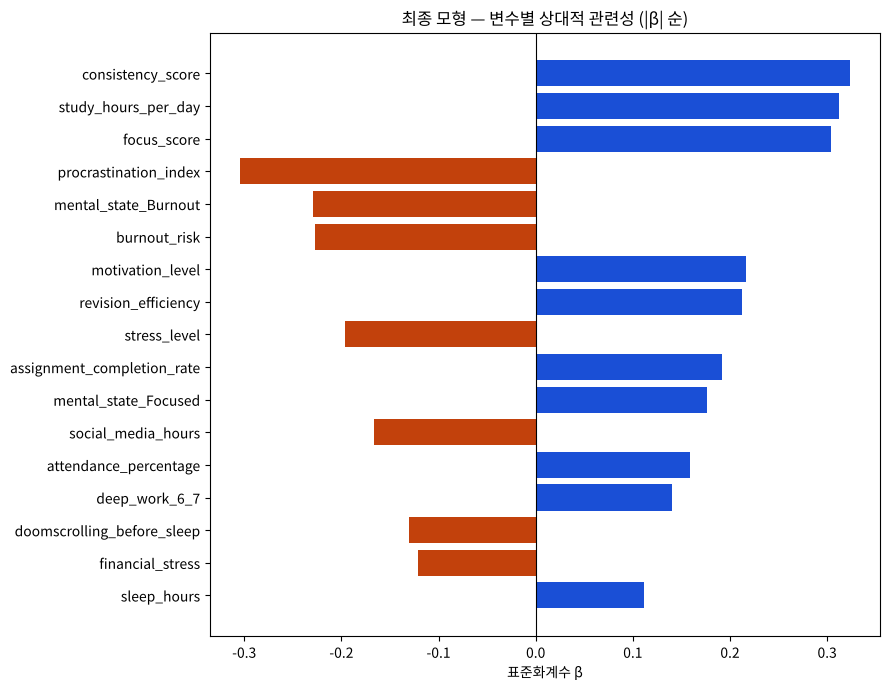

In [9]:
fig, ax = plt.subplots(figsize=(9, 7))
colors = ['#1a4fd6' if b > 0 else '#c2410c' for b in coef['beta']]
ax.barh(coef.index[::-1], coef['beta'][::-1], color=colors[::-1])
ax.axvline(0, color='black', lw=0.8)
ax.set_xlabel('표준화계수 β')
ax.set_title('최종 모형 — 변수별 상대적 관련성 (|β| 순)')
fig.tight_layout()
fig.savefig('out/04_표준화계수.png', dpi=120)
plt.show()

**해석** (다른 변수가 같다고 가정할 때)
- 꾸준함 점수 1점 ↑ → 평균 2.1점 ↑, 하루 공부시간 1시간 ↑ → 4.0점 ↑, 집중도 1점 ↑ → 2.0점 ↑, 미루기 지수 1점 ↑ → 2.0점 ↓
- 심리상태 Burnout은 Balanced 대비 9.8점 ↓, Focused는 7.7점 ↑
- 집중학습 6~7회 집단은 0~5회 대비 6.0점 ↑, 취침 전 스마트폰 사용 집단은 4.9점 ↓
- 상대적 관련성(|β|)은 꾸준함(0.32) > 공부시간(0.31) > 집중도(0.30) ≈ 미루기(−0.30) 순.
  단변량 Spearman 순위와 거의 같다 — 독립변수끼리 무상관이라 조건부 계수와 단순 상관이 일치한다.

## 5. 단변량 결과와 다중회귀 결과 비교

In [10]:
corr = pd.read_csv('out/03_spearman_상관.csv').set_index('변수')['rho']
cmp = pd.DataFrame({'Spearman ρ (03)': corr.reindex(cont_vars), 'β (04)': coef['beta'].reindex(cont_vars)})
cmp['순위 ρ'] = cmp['Spearman ρ (03)'].abs().rank(ascending=False).astype(int)
cmp['순위 β'] = cmp['β (04)'].abs().rank(ascending=False).astype(int)
cmp.to_csv('out/04_단변량_vs_회귀.csv')
cmp.sort_values('순위 β')

,Spearman ρ (03),β (04),순위 ρ,순위 β
consistency_score,0.3230,0.3231,1,1
study_hours_per_day,0.3060,0.3126,2,2
focus_score,0.2850,0.3045,3,3
procrastination_index,-0.2770,-0.3040,4,4
burnout_risk,-0.2520,-0.2273,5,5
motivation_level,0.2010,0.2161,7,6
revision_efficiency,0.2160,0.2128,6,7
stress_level,-0.1780,-0.1960,9,8
assignment_completion_rate,0.1520,0.1916,11,9
social_media_hours,-0.1820,-0.1669,8,10


## 6. 정리

- 최종 모형 (변수 17개): R² = 0.819, adj. R² = 0.817, RMSE = 7.94점, MAE = 6.35점. 네 가정 모두 만족.
- 설명력이 가장 큰 변수는 꾸준함·공부시간·집중도·미루기 — 전부 학생이 바꿀 수 있는 **학습 습관**.
  나이·성별·거주지·진로·학습 스타일 같은 고정 변수는 모두 비유의.
- 한계
  - 합성 데이터: 독립변수끼리 완전 무상관이라 실제 학생 데이터의 구조와 다르다. R² 0.82를 일반화할 수 없다.
  - 횡단면 데이터: 인과가 아니라 연관성. "공부시간을 늘리면 4점 오른다"는 개입 효과가 아니다.
  - 같은 데이터로 변수 선택·그룹화·모형 선정·성능 계산을 모두 했다 → 성능이 과대평가됐을 수 있다.
  - 종속변수 절단: 0~100 밖 예측이 생긴다.